# Disaster Tweet Classification — start here

Two proposed methods: **MLP** and **1D CNN**. Their trained results are already saved. Run cells in order to inspect them. Select the project's `.venv/bin/python` as the notebook interpreter in your editor; the notebook does not retrain automatically.

Read `README.md` first. The dataset is Kaggle's Disaster Tweets, acquired from a pinned public mirror. The report and provenance explain this choice.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert (ROOT / 'src/project.py').exists(), 'Open this notebook from the DL Project folder'
sys.path.insert(0, str(ROOT / 'src'))
import pandas as pd
from IPython.display import display, Image, Markdown
from project import clean, predict, MLP, CNN, CONFIG
print(ROOT)

/Users/shreyaroshan/Desktop/DL Project


## 1. Inspect raw data and labels
The competition test file is unlabeled. Local test metrics use a held-out part of the labeled training file.

,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake M...,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are ...,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation or...",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as ...,1


target
0    4342
1    3271
Name: count, dtype: int64

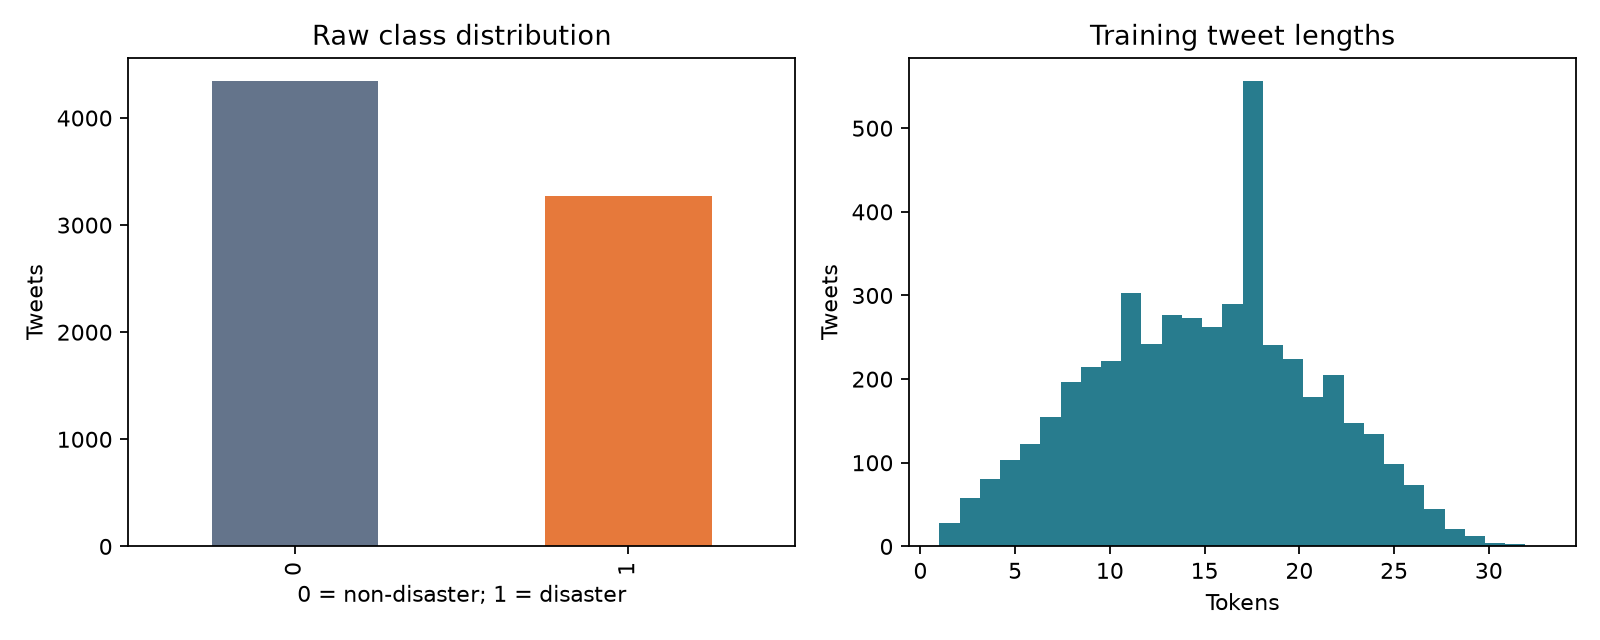

In [2]:
raw = pd.read_csv(ROOT/'data/raw/train.csv')
display(raw.head())
display(raw.target.value_counts())
display(Image(filename=str(ROOT/'reports/eda.png')))

## 2. Understand preprocessing
Negation remains; URL and mention identities are replaced; hashtag words are retained. Vocabulary is fitted only on the training partition.

In [3]:
print(clean('NOT a #disaster @friend https://example.com'))
print(json.dumps(json.loads((ROOT/'reports/eda.json').read_text()), indent=2))

not a disaster usertoken urltoken
{
  "raw_rows": 7613,
  "raw_class_counts": {
    "0": 4342,
    "1": 3271
  },
  "missing_metadata": {
    "keyword": 61,
    "location": 2533
  },
  "excluded_conflicting_or_empty_rows": 282,
  "conflicting_normalized_texts": 79,
  "removed_same_label_duplicates": 516,
  "retained_rows": 6815,
  "vocabulary_size": 12089,
  "splits": {
    "train": {
      "rows": 4770,
      "positive": 1942
    },
    "validation": {
      "rows": 1022,
      "positive": 416
    },
    "test": {
      "rows": 1023,
      "positive": 416
    }
  },
  "train_length_percentiles": {
    "50": 15.0,
    "90": 23.0,
    "95": 25.0,
    "99": 27.0,
    "100": 33.0
  },
  "raw_sha256": "61111c6dc31eaffa34d1e1fa62e2395325c9bc3b38bba1941a5f1ed9b3fa60df"
}


## 3. Inspect architectures
MLP averages embeddings and loses word order. CNN uses trainable filters spanning 3, 4 and 5 tokens to represent local phrases.

In [4]:
vocab=json.loads((ROOT/'data/processed/vocabulary.json').read_text())
print(MLP(len(vocab), CONFIG))
print(CNN(len(vocab), CONFIG))

MLP(
  (embedding): Embedding(12089, 128, padding_idx=0)
  (head): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.4, inplace=False)
    (3): Linear(in_features=64, out_features=1, bias=True)
  )
)
CNN(
  (embedding): Embedding(12089, 128, padding_idx=0)
  (convs): ModuleList(
    (0): Conv1d(128, 64, kernel_size=(3,), stride=(1,))
    (1): Conv1d(128, 64, kernel_size=(4,), stride=(1,))
    (2): Conv1d(128, 64, kernel_size=(5,), stride=(1,))
  )
  (head): Sequential(
    (0): Dropout(p=0.4, inplace=False)
    (1): Linear(in_features=192, out_features=1, bias=True)
  )
)


## 4. Compare measured results
These are preliminary results from one seed, using the same held-out tweets and threshold 0.5.

,model,accuracy,precision,recall,f1,validation_f1,best_epoch,epochs_run,training_seconds,parameters,device
0,mlp,0.758553,0.778878,0.567308,0.656467,0.654494,7,11,1.607450,1555713,cpu
1,cnn,0.759531,0.751479,0.610577,0.673740,0.676393,6,10,49.363429,1646081,cpu


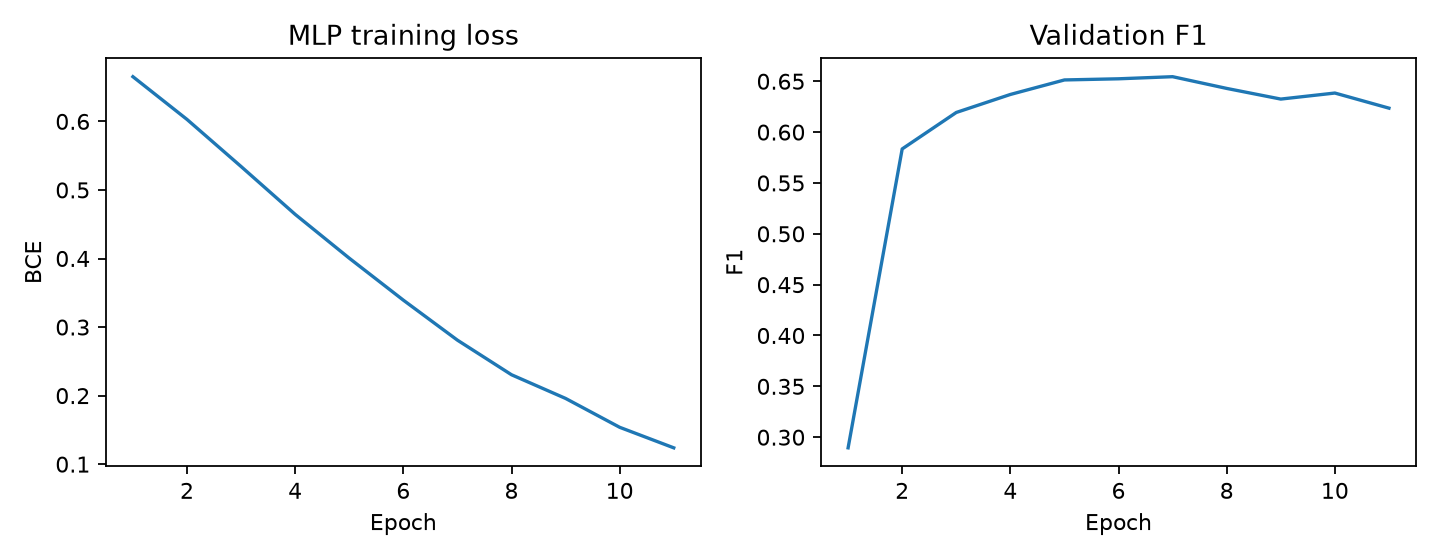

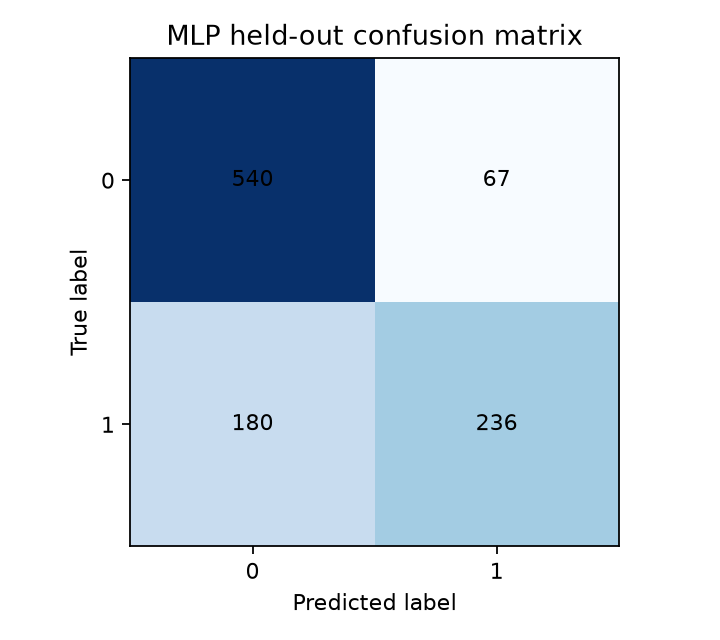

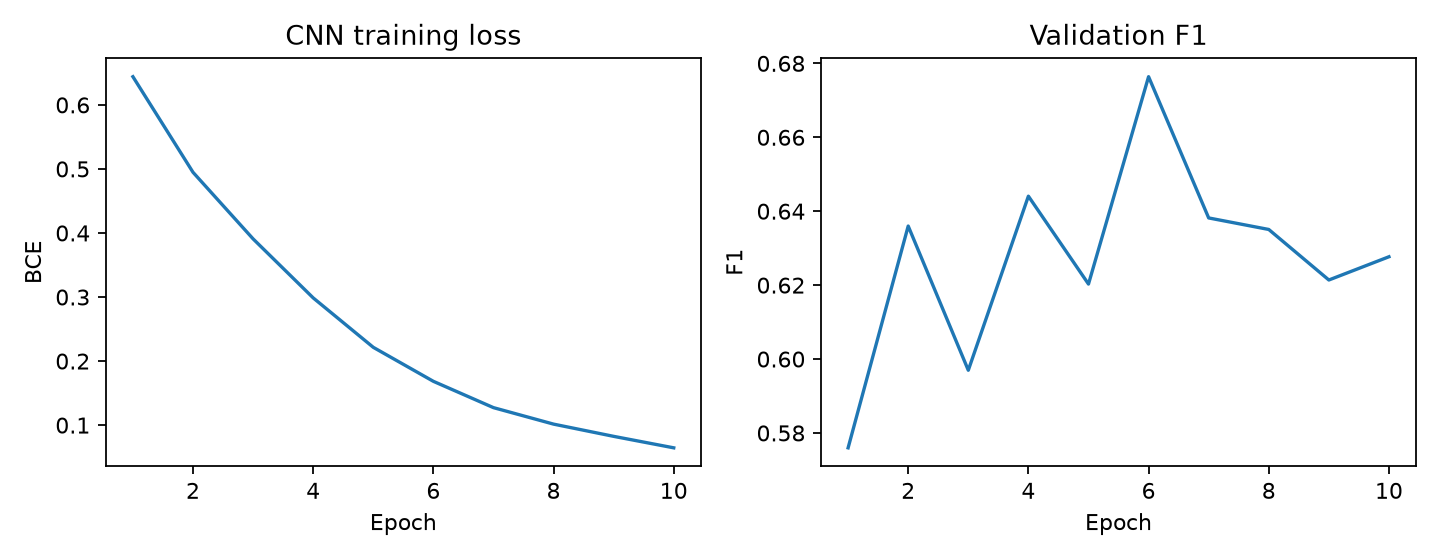

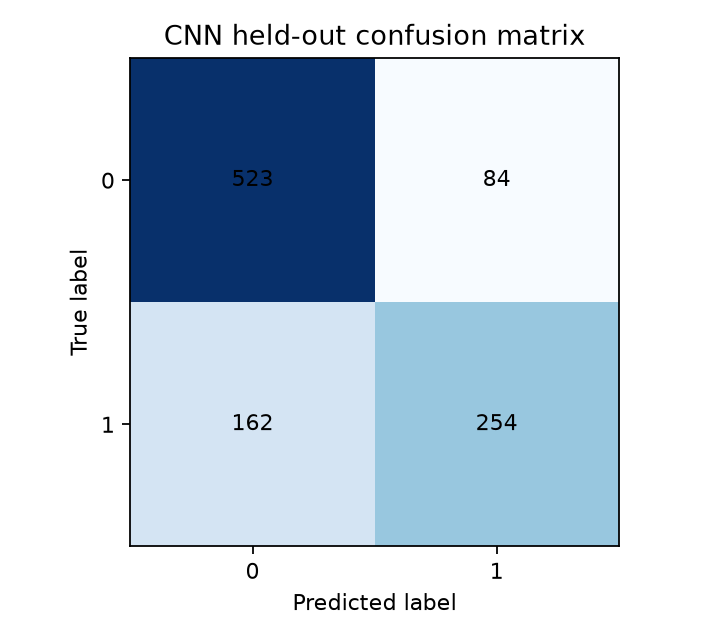

In [5]:
display(pd.read_csv(ROOT/'reports/comparison.csv'))
for model in ['mlp','cnn']:
    display(Image(filename=str(ROOT/f'reports/{model}_learning.png')))
    display(Image(filename=str(ROOT/f'reports/{model}_confusion.png')))

## 5. Try your own tweets
Change the examples below. Probabilities are uncalibrated and predictions may be wrong.

In [6]:
for text in ['Flood waters have entered several homes', 'This movie was a disaster']:
    print(text)
    for model in ['mlp','cnn']: print(predict(model,text))

Flood waters have entered several homes
{'model': 'mlp', 'disaster_probability': 0.9476423859596252, 'prediction': 1, 'label': 'disaster'}


{'model': 'cnn', 'disaster_probability': 0.2659006416797638, 'prediction': 0, 'label': 'non-disaster'}
This movie was a disaster


{'model': 'mlp', 'disaster_probability': 0.9356184601783752, 'prediction': 1, 'label': 'disaster'}


{'model': 'cnn', 'disaster_probability': 0.6822582483291626, 'prediction': 1, 'label': 'disaster'}


## 6. Review real errors
Add your own category and explanation in the exported error files. Do not change labels merely because the model disagrees.

In [7]:
display(pd.read_csv(ROOT/'reports/cnn_errors.csv').head(10))

,id,text,target,probability,prediction,review_category,review_notes
0,6631,@Bilsko and suddenly I'm inundated with resear...,1,0.020695,0,NaN,NaN
1,6184,@jasoncundy05 Chelsea need to hijack Man Utd d...,0,0.689826,1,NaN,NaN
2,5029,I liked a @YouTube video http://t.co/YdgiUYdqg...,0,0.598919,1,NaN,NaN
3,2982,Perspectives on the Grateful Dead: Critical Wr...,1,0.297180,0,NaN,NaN
4,8802,my dad said I look thinner than usual but real...,1,0.075059,0,NaN,NaN
5,8125,Why weren't they taken back to Africa once res...,1,0.082910,0,NaN,NaN
6,8266,@BLutz10 People aren't rioting because justice...,1,0.429042,0,NaN,NaN
7,9991,@author_mike Amen today is the Day of Salvatio...,1,0.026730,0,NaN,NaN
8,6624,This is set to become a huge one month wonder....,1,0.220611,0,NaN,NaN
9,4116,ItÛªs time to do away with drought.Check out ...,1,0.321201,0,NaN,NaN


## 7. Reproduce training when ready

Run these in Terminal from the project folder. Training overwrites saved artifacts; copy them first to preserve a comparison.

```bash
./.venv/bin/python src/project.py train
./.venv/bin/python -m unittest discover -s tests -v
./.venv/bin/python src/build_report.py
```

The literature review, remaining-model timeline, contribution blanks and disclosure are in `reports/`. Team members must complete real contributions and signatures before submission.